# Limpieza de Datos y Recomendaciones con Modelos Generativos
## TC2004B - Análisis de Ciencia de Datos
Steffany Mishell Lara Muy
A00838589

Objetivo: Aplicar técnicas de análisis exploratorio y modelado generativo para explorar patrones de consumo, detectar comportamientos de usuarios y genenerar recomendaciones automáticas o explicaciones de comportamiento de consumo usando un modelo tipo GTP.

### Análisis de Datos

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_sucio = pd.read_csv("ordenes-consumos.csv")
'''
Para comprender los datos
print(df_sucio.describe())
print(df_sucio.isna())
print(df_sucio.isnull())
print(df_sucio.isnull().sum())
'''
print(df_sucio.info())

#Columnas con valores NA
na = []
null = []
total_filas = df_sucio.shape[0]

for columna in df_sucio.columns:
    na_ratio = df_sucio[columna].isna().sum() / total_filas
    null_ratio = df_sucio[columna].isnull().sum() / total_filas
    if round(na_ratio, 2) > 0.5 or round(null_ratio, 2) > 0.5:
        na.append(columna)
        null.append(columna)
print(na,null," fueron eliminados :)")

#elimino estos porque más del 50% son Null o NA y no quiero rellenar con tantos datos sintéticos
df_sucio = df_sucio.drop(columns=list(set(na + null)))

#Procesamiento de Datos



df_sucio = df_sucio.drop_duplicates()

#ahora los datos que tienen poquitos null y na serán rellenados numericos mediana por el tipo de datos y categoricos moda
num_cols = df_sucio.select_dtypes(include=np.number).columns
df_sucio[num_cols] = df_sucio[num_cols].fillna(df_sucio[num_cols].median())
cat_cols = df_sucio.select_dtypes(include="object").columns
df_sucio[cat_cols] = df_sucio[cat_cols].fillna("desconocido")



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18425 entries, 0 to 18424
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   NumeroProveedor            18425 non-null  int64  
 1   OrderID                    18425 non-null  int64  
 2   FechaConsumo               18425 non-null  object 
 3   HoraConsumo                18425 non-null  object 
 4   FechaEncuesta              17334 non-null  object 
 5   FechaEvidenciaAdjunta      7604 non-null   object 
 6   NumeroSocioConsumidor      18425 non-null  int64  
 7   NombreConsumidor           18425 non-null  object 
 8   NombreMesero               18398 non-null  object 
 9   MontoCompraSinPropina      18425 non-null  float64
 10  CargoPorServicio           18425 non-null  float64
 11  MontoPropina               18425 non-null  float64
 12  MontoTotal                 18425 non-null  float64
 13  1-TC Stripe                18423 non-null  flo

In [4]:
df_sucio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18425 entries, 0 to 18424
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   NumeroProveedor         18425 non-null  int64  
 1   OrderID                 18425 non-null  int64  
 2   FechaConsumo            18425 non-null  object 
 3   HoraConsumo             18425 non-null  object 
 4   FechaEncuesta           18425 non-null  object 
 5   NumeroSocioConsumidor   18425 non-null  int64  
 6   NombreConsumidor        18425 non-null  object 
 7   NombreMesero            18425 non-null  object 
 8   MontoCompraSinPropina   18425 non-null  float64
 9   CargoPorServicio        18425 non-null  float64
 10  MontoPropina            18425 non-null  float64
 11  MontoTotal              18425 non-null  float64
 12  1-TC Stripe             18425 non-null  float64
 13  5-Saldo Clubers         18425 non-null  float64
 14  6-PayPal                18425 non-null

        NombreMesero  MontoPropina
0    Hector Camarena      14021.07
1      Felipe Zuñiga      11890.10
2    Pablo Bocanegra      11711.78
3       Nelly Pineda       7116.96
4      Claudia Avila       6946.55
..               ...           ...
432            Jenny          0.00
433     Joel Eduardo          0.00
434  Jorge Contreras          0.00
435    Jose Casanova          0.00
436    Omar Gonzalez          0.00

[437 rows x 2 columns]


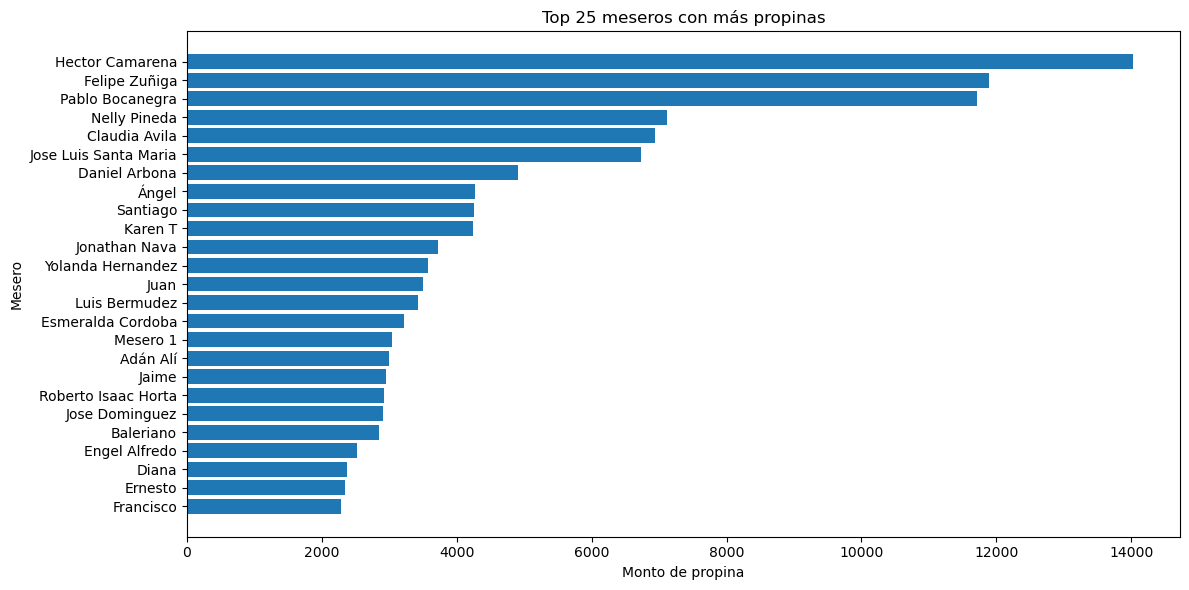

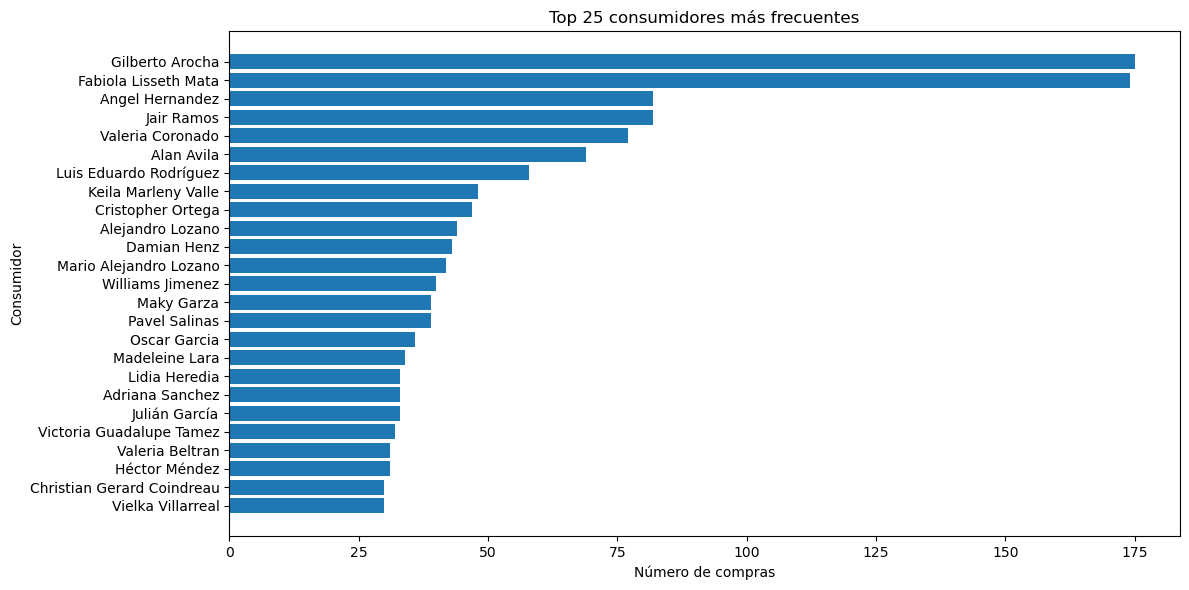

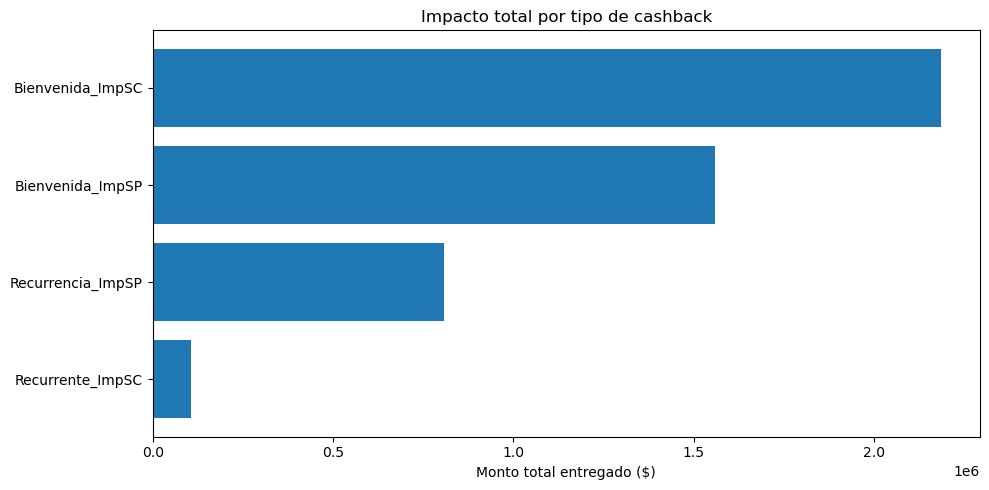

In [6]:
#Actividad


#-----------------------------------------1. ¿Qué meseros reciben más propinas?
df=df_sucio.copy()
propinas_mesero = (
    df.groupby("NombreMesero")["MontoPropina"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
print(propinas_mesero)
top_50 = propinas_mesero.head(25)

plt.figure(figsize=(12, 6))
plt.barh(top_50["NombreMesero"], top_50["MontoPropina"])
plt.title("Top 25 meseros con más propinas")
plt.xlabel("Monto de propina")
plt.ylabel("Mesero")
plt.gca().invert_yaxis()  # Para que el más alto aparezca arriba
plt.tight_layout()
plt.show()

#-----------------------------------------2. ¿Cuáles son los consumidores más frecuentes? 
consumidores_frecuentes = (
    df.groupby("NombreConsumidor")
    .size()
    .sort_values(ascending=False)
    .head(25)  # Solo top 25
)

# Gráfica
plt.figure(figsize=(12, 6))
plt.barh(consumidores_frecuentes.index, consumidores_frecuentes.values)
plt.title("Top 25 consumidores más frecuentes")
plt.xlabel("Número de compras")
plt.ylabel("Consumidor")
plt.gca().invert_yaxis()  # El más frecuente arriba
plt.tight_layout()
plt.show()


#-----------------------------------------3. Qué tipo de cashback tiene más impacto?
impactos = {
    "Bienvenida_ImpSC": df["Bienvenida_ImpSC"].sum(),
    "Recurrente_ImpSC": df["Recurrente_ImpSC"].sum(),
    "Bienvenida_ImpSP": df["Bienvenida_ImpSP"].sum(),
    "Recurrencia_ImpSP": df["Recurrencia_ImpSP"].sum()
}

# Convertimos a DataFrame para ordenar y visualizar
impactos_df = pd.DataFrame(list(impactos.items()), columns=["TipoCashback", "MontoTotal"])
impactos_df = impactos_df.sort_values(by="MontoTotal", ascending=False).reset_index(drop=True)

# Opcional: graficar
plt.figure(figsize=(10,5))
plt.barh(impactos_df["TipoCashback"], impactos_df["MontoTotal"])
plt.title("Impacto total por tipo de cashback")
plt.xlabel("Monto total entregado ($)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



## Detectar comportamientos de usuarios nuevos vs. recurrentes.

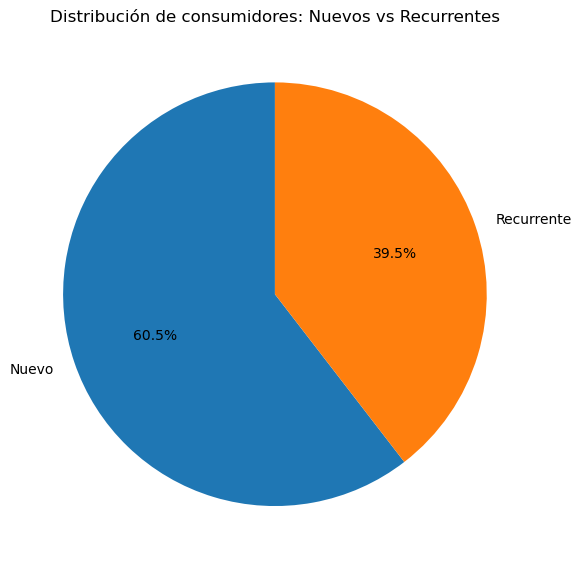

tipo_consumidor
Nuevo         11139
Recurrente     7286
Name: count, dtype: int64
9879


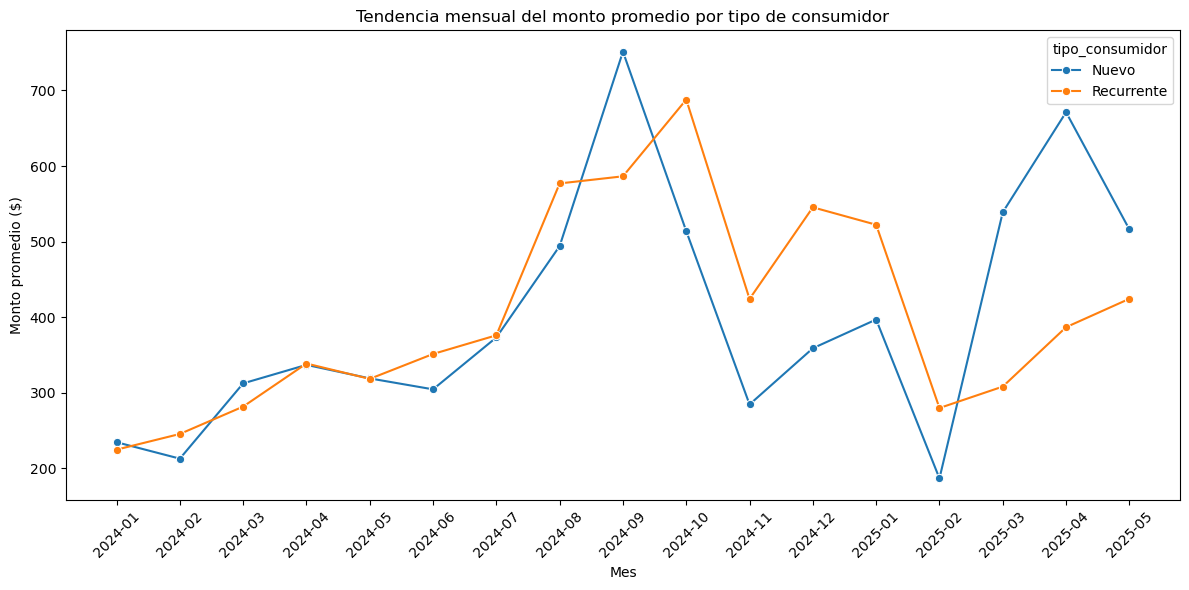

Analizar si hay relación entre monto y tipo de cashback recibido.
  Cashback/Descuento  MontoTotal
0           Cashback  274.704154
1          Descuento  520.631076


In [16]:
'''
    Parte 2: Perfilado y Segmentación
    Clasificar a los consumidores entre nuevos y recurrentes.
    
    Calcular el monto promedio por segmento y su tendencia mensual.
    
    Analizar si hay relación entre monto y tipo de cashback recibido.
'''

#-----------------------------------------1. Clasificar a los consumidores entre nuevos y recurrentes.
# 1. Asegurarse que las fechas estén en datetime
fechas = ["FechaConsumo", "HoraConsumo", "FechaEncuesta"]

for col in fechas:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')


# 2. Normalizar la fecha (sin hora)
df['FechaSolo'] = df['FechaConsumo'].dt.normalize()

# 3. Crear la columna de tipo consumidor
df['tipo_consumidor'] = (
    df['FechaSolo'] ==
    df.groupby('NumeroSocioConsumidor')['FechaSolo'].transform('min')
).map({True: 'Nuevo', False: 'Recurrente'})


# Contar cuántos hay de cada tipo
conteo = df['tipo_consumidor'].value_counts()

# Graficar
plt.figure(figsize=(6, 6))
plt.pie(conteo, labels=conteo.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribución de consumidores: Nuevos vs Recurrentes')
plt.tight_layout()
plt.show()

print(df['tipo_consumidor'].value_counts())

print(df['NumeroSocioConsumidor'].nunique())  

#-----------------------------------------2. Calcular el monto promedio por segmento y su tendencia mensual.


# Crear columna de mes (periodo)
df['Mes'] = df['FechaConsumo'].dt.to_period('M')

# Agrupar por mes y tipo de consumidor
monto_mensual = df.groupby(['Mes', 'tipo_consumidor'])['MontoTotal'].mean().reset_index()

# Convertir Mes a string para que seaborn lo acepte
monto_mensual['Mes'] = monto_mensual['Mes'].astype(str)

# Graficar la tendencia mensual
plt.figure(figsize=(12, 6))
sns.lineplot(data=monto_mensual, x='Mes', y='MontoTotal', hue='tipo_consumidor', marker='o')
plt.title("Tendencia mensual del monto promedio por tipo de consumidor")
plt.ylabel("Monto promedio ($)")
plt.xlabel("Mes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



#-----------------------------------------3. Analizar si hay relación entre monto y tipo de cashback recibido.
montoCashback=df.groupby(['Cashback/Descuento'])['MontoTotal'].mean().reset_index()
print("Analizar si hay relación entre monto y tipo de cashback recibido.")
print(montoCashback)

Se evidencia que los clientes que reciben descuento están más dispuestos a pagar que los que reciben un cashback, lo cuál es interesante dado que en Clubers hicieron el cambio de cashback a descuentos y en estos datos, que pese a ser de una fuente distinta, también se refleja como aumenta el monto total gastado cuando se aplica descuento. Esto podría deberse a que para aplicar un descuento te piden un monto mínimo de consumo.

## Uso de GPT para Generación de Recomendaciones

Uso de modelo GPT (Modelos generativos)

In [7]:
pip install --upgrade openai   # se instalará >=1.13

Note: you may need to restart the kernel to use updated packages.


In [8]:
import os, textwrap, pandas as pd, openai

In [9]:
# ============================================================
#   PARTE 3 · Recomendaciones e insights con GPT (SDK v1.x)
# ============================================================

# 0) LIBRERÍAS Y CLIENTE AZURE OPENAI
# ------------------------------------------------------------

# ── cliente ──
from openai import AzureOpenAI
import textwrap, pandas as pd

client = AzureOpenAI(
    api_version    = "2024-12-01-preview",
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),   # ← SOLO la raíz
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)
DEPLOYMENT_NAME = "gpt-4"

# ------------------------------------------------------------------
# 1)  PAYLOAD MÍNIMO POR CLIENTE
# ------------------------------------------------------------------
cols = ['NumeroSocioConsumidor', 'tipo_consumidor', 'MontoTotal',
        'FechaConsumo', 'Cashback/Descuento']

ult_tx = (df.sort_values('FechaConsumo')
            .groupby('NumeroSocioConsumidor')
            .tail(1)[cols])

ultimos_30 = df[df['FechaConsumo'] >= pd.Timestamp.today() - pd.Timedelta('30D')]
freq_30d   = (ultimos_30.groupby('NumeroSocioConsumidor')['OrderID']
                       .count()
                       .rename('Frec_30d'))

payload = (ult_tx.merge(freq_30d, on='NumeroSocioConsumidor', how='left')
                  .fillna({'Frec_30d': 0}))

# ------------------------------------------------------------------
# 2)  FUNCIÓN → RECOMENDACIÓN 1-A-1
# ------------------------------------------------------------------
def recomendar_fidelizacion(fila: pd.Series) -> str:
    prompt = textwrap.dedent(f"""
        Eres analista de CRM.  Basándote en estos datos,
        genera UNA recomendación (máx. 35 palabras) para mejorar retención o ticket promedio.
        • Segmento: {fila['tipo_consumidor']}
        • Último ticket: ${fila['MontoTotal']:,.2f}
        • Frec. 30 días: {int(fila['Frec_30d'])}
        • Último cashback: {fila['Cashback/Descuento'] or 'ninguno'}
        Escribe directamente la recomendación.
    """)
    respuesta = client.chat.completions.create(
        model    = DEPLOYMENT_NAME,
        messages = [{"role": "user", "content": prompt}],
        max_tokens  = 80,
        temperature = 0.6
    )
    return respuesta.choices[0].message.content.strip()

# Ejemplo con 5 clientes aleatorios
for _, fila in payload.sample(5, random_state=1).iterrows():
    print(f"{fila['NumeroSocioConsumidor']} ➜ {recomendar_fidelizacion(fila)}")

# ------------------------------------------------------------------
# 3)  TABLA RESUMEN PARA INSIGHTS
# ------------------------------------------------------------------
df['Mes'] = df['FechaConsumo'].dt.to_period('M')
ticket_mes = (df.groupby(['Mes', 'tipo_consumidor'])['MontoTotal']
                .mean().round(2).unstack().fillna(0))

# ------------------------------------------------------------------
# 4)  FUNCIÓN → INSIGHTS AUTOMÁTICOS
# ------------------------------------------------------------------
def generar_insights(tabla: pd.DataFrame, objetivo="fidelización") -> str:
    prompt = textwrap.dedent(f"""
        Eres consultor senior de datos.  A partir de la siguiente tabla,
        presenta 3-5 insights accionables (viñetas) sobre {objetivo}.

        --- TABLA ---
        {tabla.to_string()}
        --- FIN TABLA ---
    """)
    resp = client.chat.completions.create(
        model     = DEPLOYMENT_NAME,
        messages  = [{"role": "user", "content": prompt}],
        max_tokens  = 250,
        temperature = 0.5
    )
    return resp.choices[0].message.content.strip()

print("\nINSIGHTS SOBRE TICKET MEDIO:")
print(generar_insights(ticket_mes.head(12), objetivo="crecimiento de ticket y retención"))


30021 ➜ Ofrecer un cashback incremental en función del monto del ticket para incentivar compras de mayor valor en clientes recurrentes.
49251 ➜ Ofrecer un programa de lealtad con puntos acumulables por compra que puedan canjearse por descuentos o productos exclusivos, incentivando así la repetición de compra y aumentando el ticket promedio.
46049 ➜ Implementar un programa de recompensas por fidelidad que ofrezca cashback escalonado para incentivar compras más frecuentes y aumentar el ticket promedio.
32200 ➜ Ofrecer un programa de lealtad con recompensas incrementales para motivar compras más frecuentes y aumentar el ticket promedio de los clientes recurrentes.
32786 ➜ Implementar un programa de lealtad que ofrezca recompensas incrementales por visitas frecuentes para motivar al cliente a aumentar su frecuencia de compra y ticket promedio.

INSIGHTS SOBRE TICKET MEDIO:
1. **Fomentar la retención de consumidores recurrentes**: Los consumidores recurrentes tienden a gastar más por ticket

In [13]:
print(ultimos_30)

       NumeroProveedor  OrderID FechaConsumo         HoraConsumo  \
16133               85    67723   2025-05-01 2025-05-28 12:55:00   
16134              241    67725   2025-05-01 2025-05-28 13:38:00   
16135              212    67732   2025-05-01 2025-05-28 14:30:00   
16136              241    67731   2025-05-01 2025-05-28 14:34:00   
16137              241    67733   2025-05-01 2025-05-28 14:36:00   
...                ...      ...          ...                 ...   
18203              211    70128   2025-12-05 2025-05-28 19:23:00   
18204              210    70129   2025-12-05 2025-05-28 20:09:00   
18205              210    70130   2025-12-05 2025-05-28 20:32:00   
18206              211    70131   2025-12-05 2025-05-28 21:21:00   
18207              350    70132   2025-12-05 2025-05-28 21:37:00   

      FechaEncuesta  NumeroSocioConsumidor    NombreConsumidor  \
16133    2025-05-01                  39944       Carla Bonilla   
16134    2025-05-01                  45371     Deya